In [1]:
%pip install yfinance

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 2.0/2.0 MB 18.3 MB/s  0:00:00
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ------------------ --------------------- 1.8/4.0 MB 9.1 MB/s eta 0:00:01
   ---------------------------- ----------- 2.9/4.0 MB 6.7 MB/s eta 0:00:01
   ---------------------------------------- 4.0/4.0 MB 6.2 MB/s  0:00:00

   ---- -----------------------------------  1/10 [websockets]
   ---- -----------------------------------  1/10 [websockets]
   ---- -----------------------------------  1/10 [websockets]
   ---- -----------------------------------  1/10 [websockets]
   ---- -----------------------------------  1/10 [websockets]
   -------- -------------------------------  2/10 [soupsieve]
   ------------ ---------------------------  3/10 [pycparser]
   ------------ ---------------------------  3/10 [pycparser]
   ---------------- -----------------------  4/10 [peewee]
  


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import seaborn as sns
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
#The code fetches historical price data for Bitcoin, Ethereum, Tether, and Binance Coin for the past 5 years and keeps only the Close and Volume columns for each of these cryptocurrencies.
#This cleaned data can then be used for further analysis or machine learning tasks, such as predicting future prices.


btc = yf.Ticker('BTC-USD')
prices1 = btc.history(period='5y')
prices1.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

eth = yf.Ticker('ETH-USD')
prices2 = eth.history(period='5y')
prices2.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

usdt = yf.Ticker('USDT-USD')
prices3 = usdt.history(period='5y')
prices3.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

bnb = yf.Ticker('BNB-USD')
prices4 = bnb.history(period='5y')
prices4.drop(columns=['Open', 'High', 'Low', 'Dividends', 'Stock Splits'], axis = 1, inplace = True)

In [4]:
#The parameters lsuffix and rsuffix in the join method are used to add suffixes to overlapping column names when joining two DataFrames
# This is necessary to avoid column name conflicts when the two DataFrames have columns with the same name.

p1 = prices1.join(prices2, lsuffix = ' (BTC)', rsuffix = ' (ETH)')
p2 = prices3.join(prices4, lsuffix = ' (USDT)', rsuffix = ' (BNB)')
data = p1.join(p2, lsuffix = '_', rsuffix = '_')

In [8]:
data.shape

(1827, 8)

In [5]:
data.head()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2021-10-17 00:00:00+00:00,61553.617188,29032367511,3847.104492,15908090346,1.000280,57600914728,470.625549,1646437501
2021-10-18 00:00:00+00:00,62026.078125,38055562075,3748.760254,17386204158,1.000019,66503250420,485.111023,1999805026
2021-10-19 00:00:00+00:00,64261.992188,40471196346,3877.650879,15998757133,1.000117,62387883982,488.148865,1844483840
2021-10-20 00:00:00+00:00,65992.835938,40788955582,4155.992188,20338319988,0.999940,70187915900,501.020325,1890415594
2021-10-21 00:00:00+00:00,62210.171875,45908121370,4054.322754,28220661820,1.000022,84189482202,471.256927,3081793454


In [6]:
data.tail()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,,
2026-10-13 00:00:00+00:00,83095.125000,30990542834,2496.625488,12481395844,0.999090,70449852433,741.062195,1353053958
2026-10-14 00:00:00+00:00,81562.492188,33457522700,2418.207031,13382928521,0.998739,70062551952,729.261414,1265255137
2026-10-15 00:00:00+00:00,82141.460938,41979689877,2440.479980,18599863197,0.998809,87487791972,728.668152,1698751156
2026-10-16 00:00:00+00:00,81500.804688,26591693705,2419.767334,11773801739,0.998603,63342250194,720.894043,1309402321
2026-10-17 00:00:00+00:00,81569.968750,23465986048,2430.439941,10251763712,0.998580,55767515136,721.340027,1230042880


In [7]:
data.isnull().sum()

Close (BTC)      0
Volume (BTC)     0
Close (ETH)      0
Volume (ETH)     0
Close (USDT)     0
Volume (USDT)    0
Close (BNB)      0
Volume (BNB)     0
dtype: int64

In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1827 entries, 2021-10-17 00:00:00+00:00 to 2026-10-17 00:00:00+00:00
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Close (BTC)    1827 non-null   float64
 1   Volume (BTC)   1827 non-null   int64  
 2   Close (ETH)    1827 non-null   float64
 3   Volume (ETH)   1827 non-null   int64  
 4   Close (USDT)   1827 non-null   float64
 5   Volume (USDT)  1827 non-null   int64  
 6   Close (BNB)    1827 non-null   float64
 7   Volume (BNB)   1827 non-null   int64  
dtypes: float64(4), int64(4)
memory usage: 128.5 KB


In [10]:
data.describe()

,Close (BTC),Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
count,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03,1827.000000,1.827000e+03
mean,58955.354236,3.461608e+10,2506.765056,1.757351e+10,0.999971,6.766537e+10,510.920126,1.625709e+09
std,29871.232109,2.058336e+10,878.126326,1.184230e+10,0.000662,4.223610e+10,219.622206,1.087250e+09
min,15787.284180,5.331173e+09,993.636780,2.081626e+09,0.995872,9.989859e+09,197.042999,2.038465e+08
25%,29412.204102,2.035523e+10,1810.192871,9.444933e+09,0.999663,3.930150e+10,304.748932,9.030619e+08
50%,60945.812500,3.011673e+10,2372.201904,1.497808e+10,1.000060,5.797554e+10,554.889282,1.518718e+09
75%,82547.617188,4.255977e+10,3122.963989,2.171727e+10,1.000283,8.340095e+10,642.235321,2.009017e+09
max,124752.531250,1.817464e+11,4831.348633,9.773662e+10,1.007690,3.443980e+11,1310.214355,1.182039e+10


# Exploratory Data Analysis

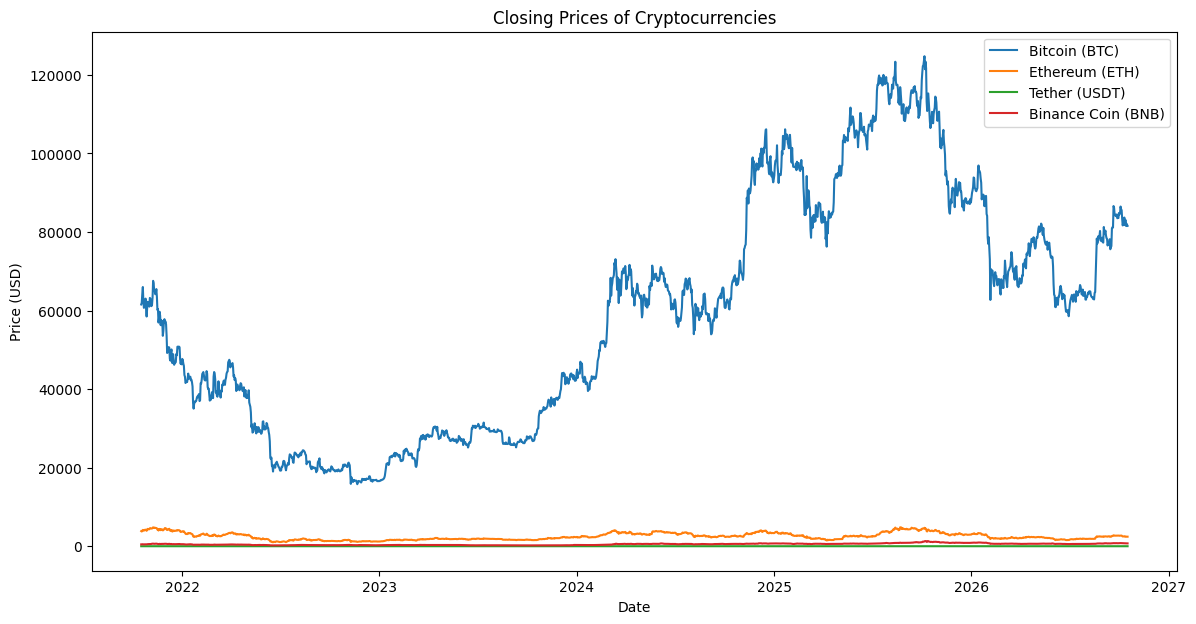

In [11]:
#Visualize the Closing Prices
# create a line plot to visualize the closing prices of all four cryptocurrencies over time:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Close (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Close (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Close (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Close (BNB)'], label='Binance Coin (BNB)')
plt.title('Closing Prices of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.show()


<Axes: xlabel='Date'>

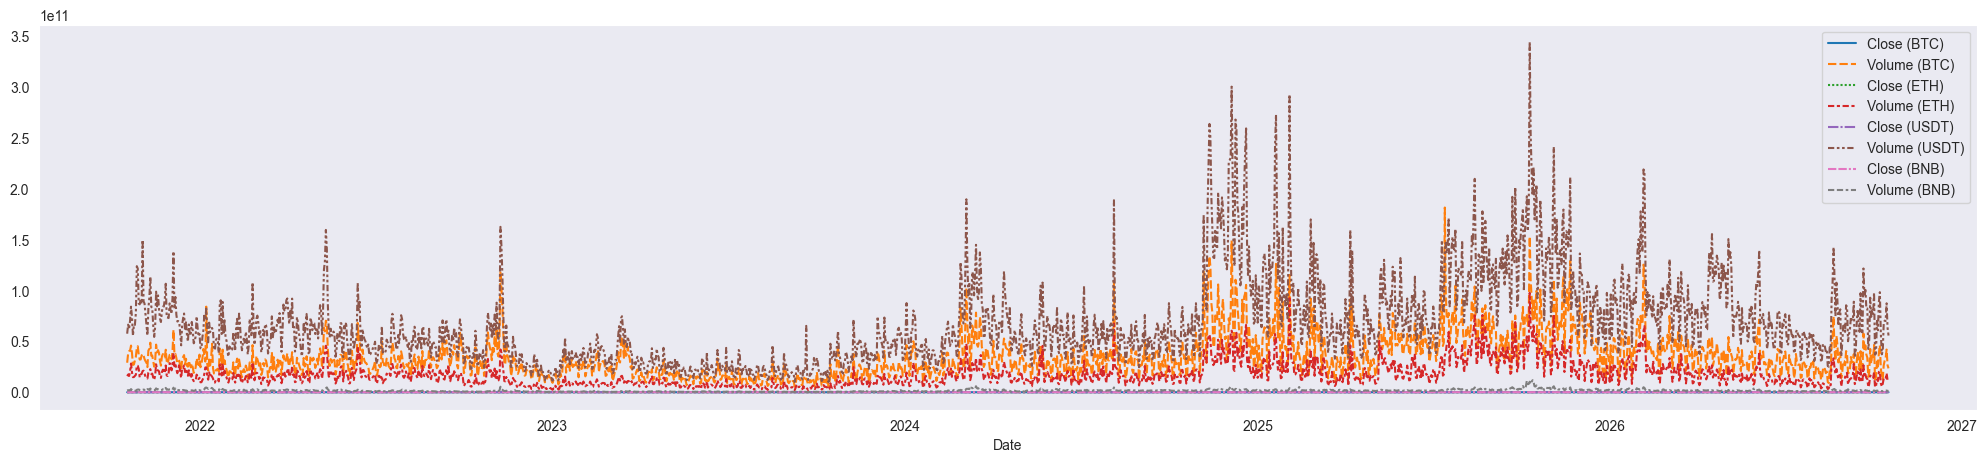

In [13]:
plt.figure(figsize = (25, 5))
sns.set_style('dark')
sns.lineplot(data=data)

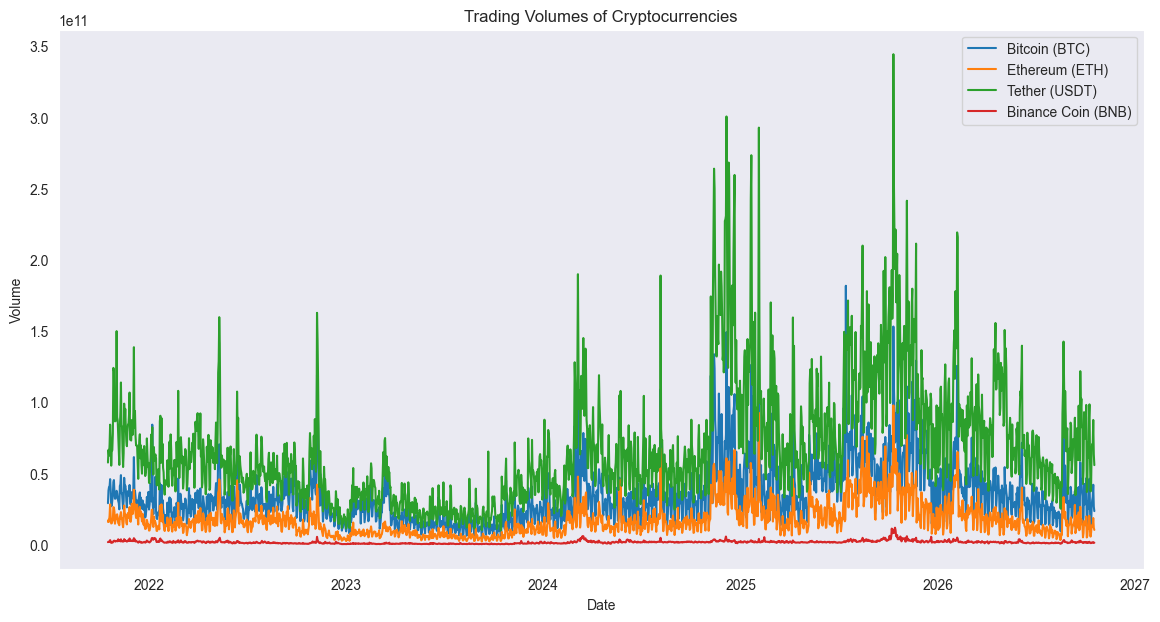

In [14]:
# Visualize the Trading Volumes
#Let's visualize the trading volumes of all four cryptocurrencies:
plt.figure(figsize=(14, 7))
plt.plot(data.index, data['Volume (BTC)'], label='Bitcoin (BTC)')
plt.plot(data.index, data['Volume (ETH)'], label='Ethereum (ETH)')
plt.plot(data.index, data['Volume (USDT)'], label='Tether (USDT)')
plt.plot(data.index, data['Volume (BNB)'], label='Binance Coin (BNB)')
plt.title('Trading Volumes of Cryptocurrencies')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.legend()
plt.show()


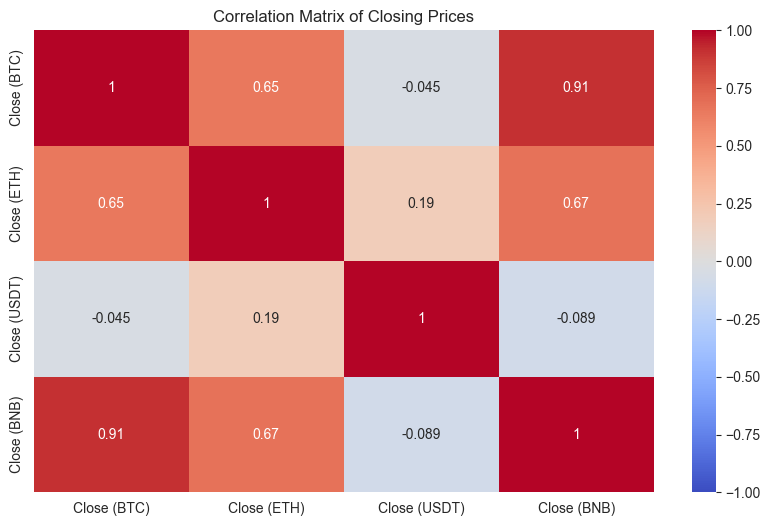

In [15]:
 #Correlation Analysis
#We'll analyze the correlation between the closing prices of the cryptocurrencies:
# Calculate the correlation matrix

corr_matrix = data[['Close (BTC)', 'Close (ETH)', 'Close (USDT)', 'Close (BNB)']].corr()

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Closing Prices')
plt.show()

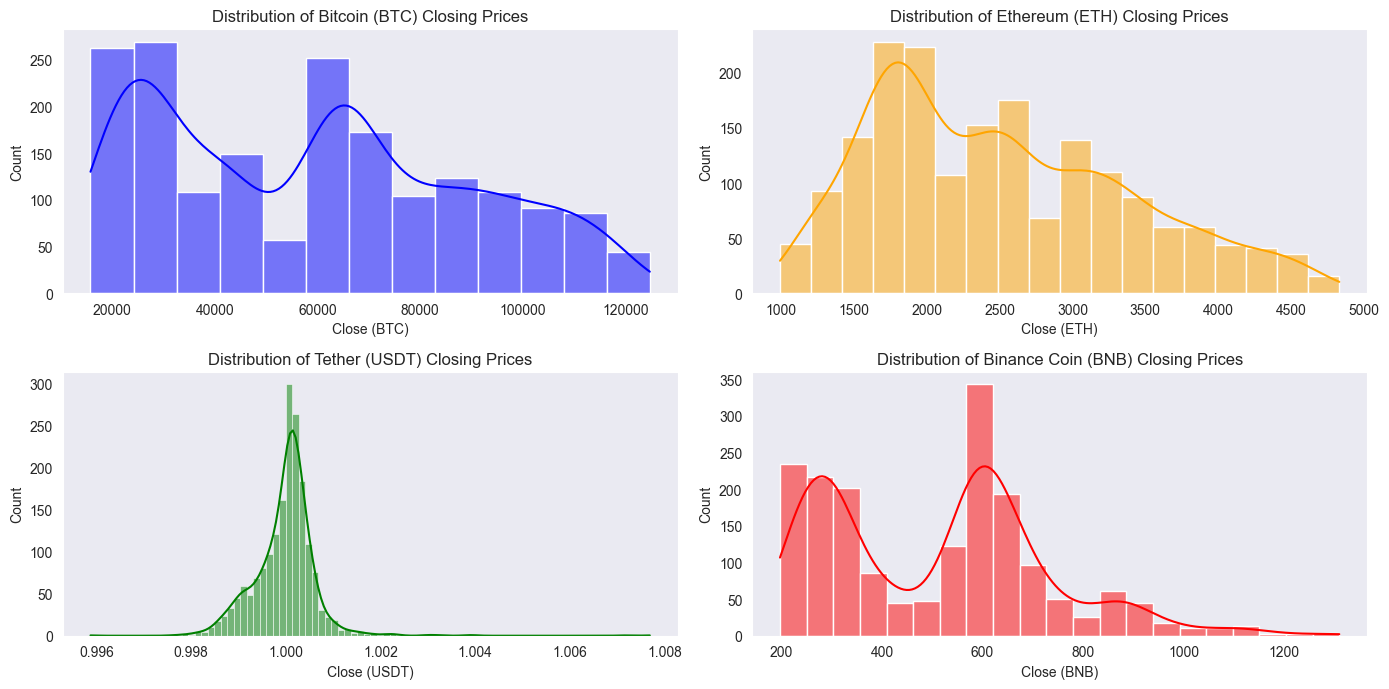

In [16]:
# Distribution of Closing Prices
#Let's plot the distribution of closing prices for each cryptocurrency:


plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
sns.histplot(data['Close (BTC)'], kde=True, color='blue')
plt.title('Distribution of Bitcoin (BTC) Closing Prices')

plt.subplot(2, 2, 2)
sns.histplot(data['Close (ETH)'], kde=True, color='orange')
plt.title('Distribution of Ethereum (ETH) Closing Prices')

plt.subplot(2, 2, 3)
sns.histplot(data['Close (USDT)'], kde=True, color='green')
plt.title('Distribution of Tether (USDT) Closing Prices')

plt.subplot(2, 2, 4)
sns.histplot(data['Close (BNB)'], kde=True, color='red')
plt.title('Distribution of Binance Coin (BNB) Closing Prices')

plt.tight_layout()
plt.show()

array([[<Axes: title={'center': 'Close (BTC)'}>,
        <Axes: title={'center': 'Volume (BTC)'}>,
        <Axes: title={'center': 'Close (ETH)'}>,
        <Axes: title={'center': 'Volume (ETH)'}>],
       [<Axes: title={'center': 'Close (USDT)'}>,
        <Axes: title={'center': 'Volume (USDT)'}>,
        <Axes: title={'center': 'Close (BNB)'}>,
        <Axes: title={'center': 'Volume (BNB)'}>]], dtype=object)

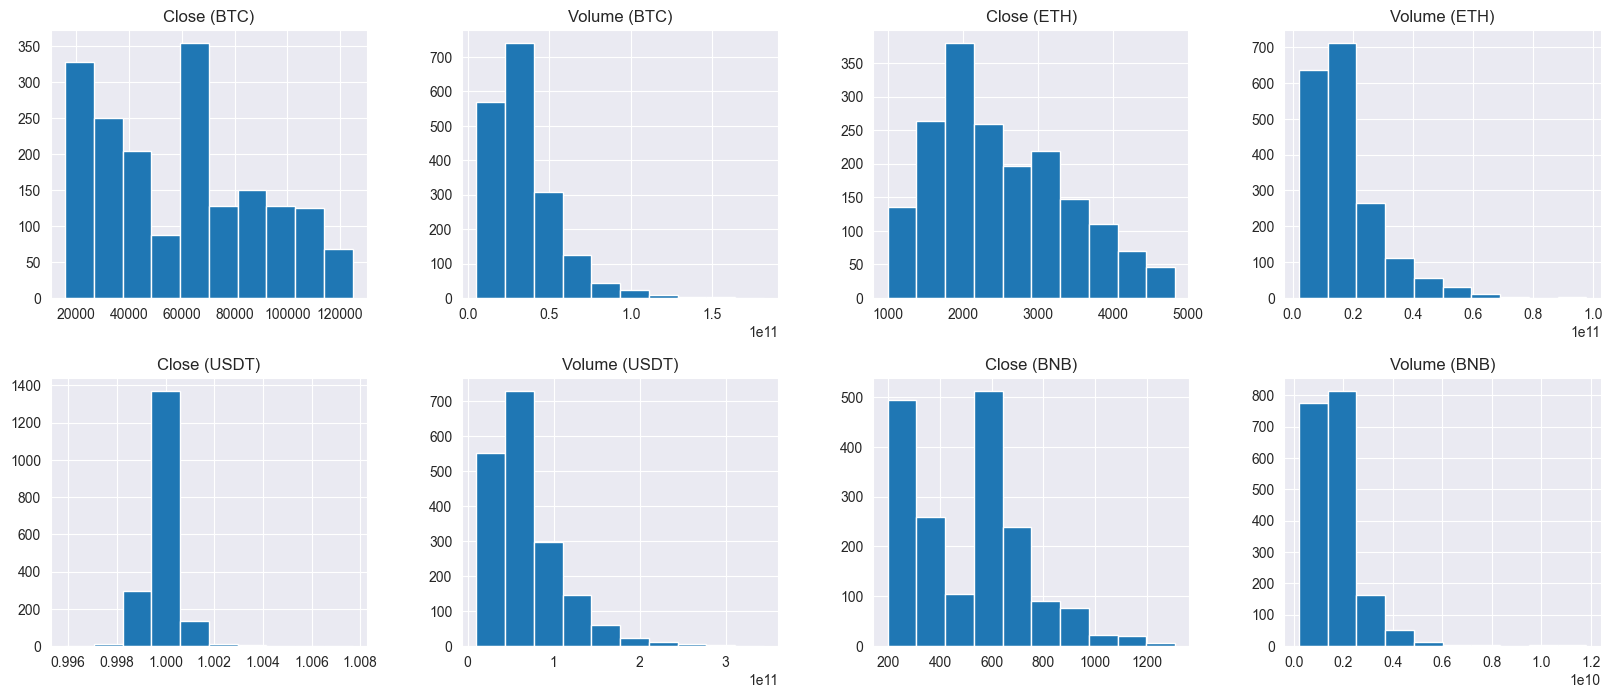

In [17]:
data.hist(figsize=(20, 8), layout=(2, 4))

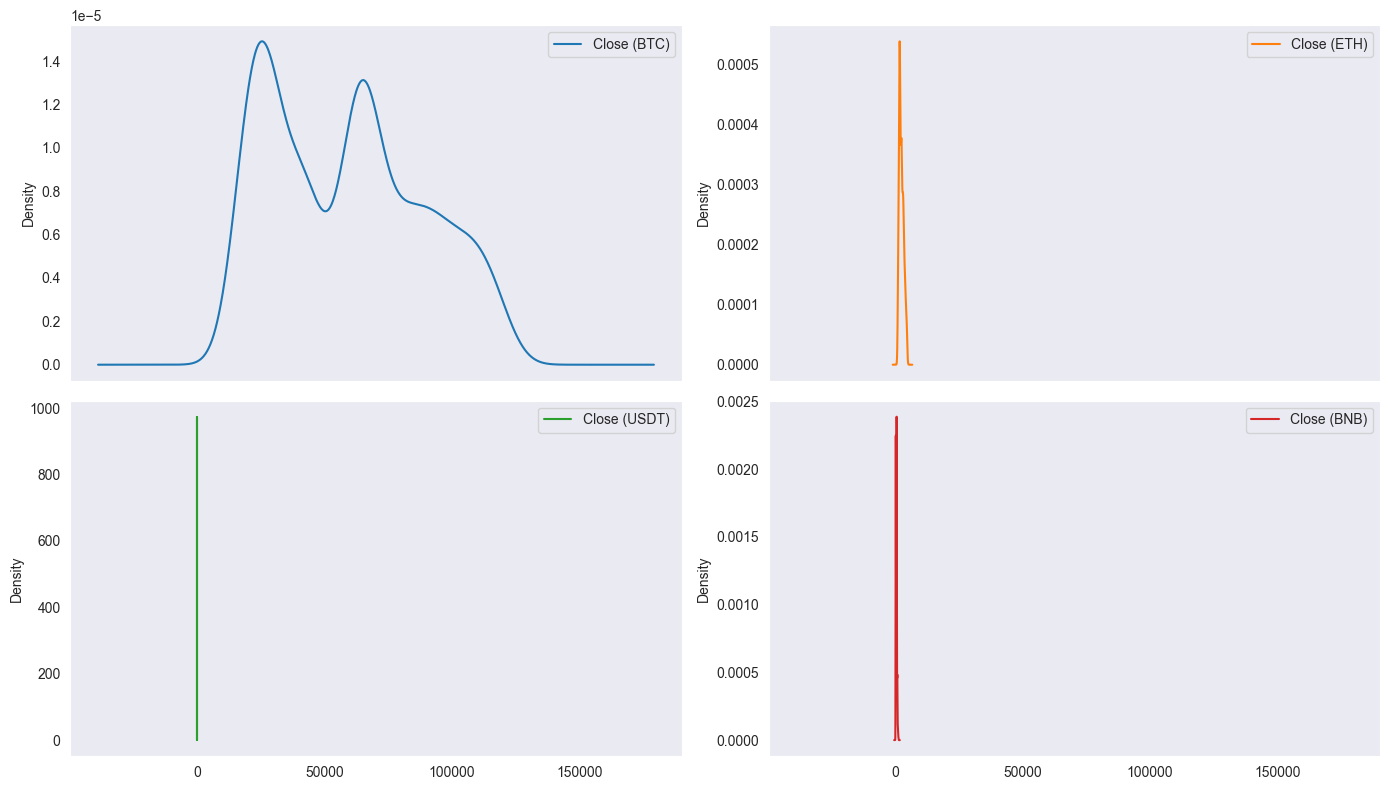

In [18]:
close_columns = [
    'Close (BTC)',
    'Close (ETH)',
    'Close (USDT)',
    'Close (BNB)'
]

data[close_columns].plot(
    kind='kde',
    subplots=True,
    layout=(2, 2),
    figsize=(14, 8)
)

plt.tight_layout()
plt.show()

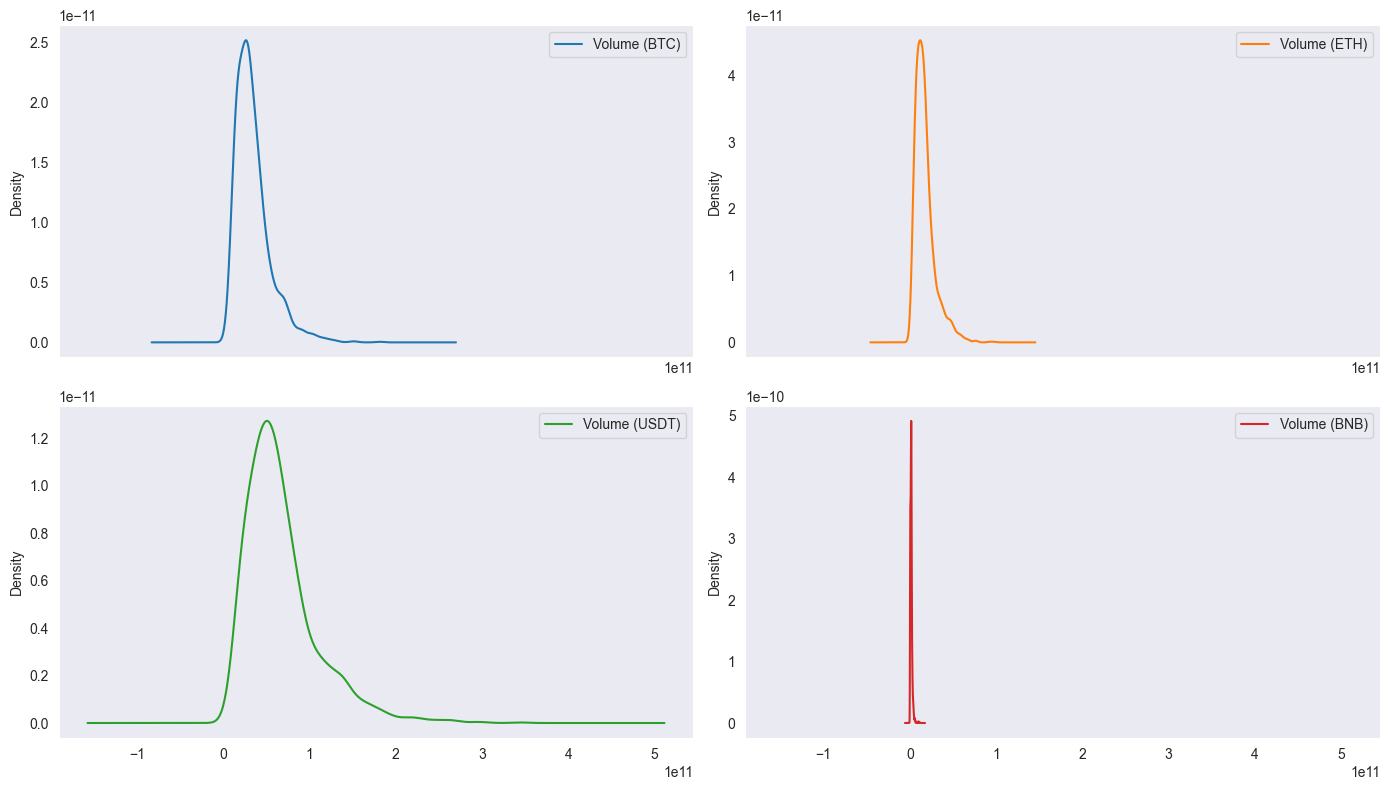

In [19]:
volume_columns = [
    'Volume (BTC)',
    'Volume (ETH)',
    'Volume (USDT)',
    'Volume (BNB)'
]

data[volume_columns].plot(
    kind='kde',
    subplots=True,
    layout=(2, 2),
    figsize=(14, 8)
)

plt.tight_layout()
plt.show()

# Data Pre-processing

In [20]:
X = data.drop(columns = ['Close (BTC)'], axis = 1)
Y = data.loc[:, 'Close (BTC)']

In [21]:
X.head()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2021-10-17 00:00:00+00:00,29032367511,3847.104492,15908090346,1.000280,57600914728,470.625549,1646437501
2021-10-18 00:00:00+00:00,38055562075,3748.760254,17386204158,1.000019,66503250420,485.111023,1999805026
2021-10-19 00:00:00+00:00,40471196346,3877.650879,15998757133,1.000117,62387883982,488.148865,1844483840
2021-10-20 00:00:00+00:00,40788955582,4155.992188,20338319988,0.999940,70187915900,501.020325,1890415594
2021-10-21 00:00:00+00:00,45908121370,4054.322754,28220661820,1.000022,84189482202,471.256927,3081793454


In [22]:
X.tail()

,Volume (BTC),Close (ETH),Volume (ETH),Close (USDT),Volume (USDT),Close (BNB),Volume (BNB)
Date,,,,,,,
2026-10-13 00:00:00+00:00,30990542834,2496.625488,12481395844,0.999090,70449852433,741.062195,1353053958
2026-10-14 00:00:00+00:00,33457522700,2418.207031,13382928521,0.998739,70062551952,729.261414,1265255137
2026-10-15 00:00:00+00:00,41979689877,2440.479980,18599863197,0.998809,87487791972,728.668152,1698751156
2026-10-16 00:00:00+00:00,26591693705,2419.767334,11773801739,0.998603,63342250194,720.894043,1309402321
2026-10-17 00:00:00+00:00,23465986048,2430.439941,10251763712,0.998580,55767515136,721.340027,1230042880


In [24]:
Y.head()


Date
2021-10-17 00:00:00+00:00    61553.617188
2021-10-18 00:00:00+00:00    62026.078125
2021-10-19 00:00:00+00:00    64261.992188
2021-10-20 00:00:00+00:00    65992.835938
2021-10-21 00:00:00+00:00    62210.171875
Name: Close (BTC), dtype: float64

In [ ]:
# Split the data into training and testing sets

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=0)

In [ ]:
# Print the shapes of the resulting datasets

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape: {X_test.shape}')
print(f'y_train shape: {Y_train.shape}')
print(f'y_test shape: {Y_test.shape}')

X_train shape: (1461, 7)
X_test shape: (366, 7)
y_train shape: (1461,)
y_test shape: (366,)


In [27]:
#SelectKBest
#SelectKBest is a feature selection method provided by scikit-learn (sklearn) that selects the top k features based on a specified scoring function.
#This function evaluates each feature independently and selects those that have the strongest relationship with the target variable.

#Parameters
#k: Specifies the number of top features to select. In your case, k=4 indicates that you want to select the top 4 features

from sklearn.feature_selection import SelectKBest

fs = SelectKBest(k=4)
X_train = fs.fit_transform(X_train, Y_train)
X_test = fs.transform(X_test)

c:\Users\raymo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\feature_selection\_univariate_selection.py:107: RuntimeWarning: invalid value encountered in divide
  msw = sswn / float(dfwn)


In [28]:
mask = fs.get_support()
selected_features = X.columns[mask]
print("Selected Features:", selected_features) 

Selected Features: Index(['Close (USDT)', 'Volume (USDT)', 'Close (BNB)', 'Volume (BNB)'], dtype='object')


In [29]:
X_train

array([[9.99406993e-01, 4.92226602e+10, 2.38164474e+02, 1.60936157e+09],
       [9.99260008e-01, 6.88667356e+10, 3.00504059e+02, 1.76362495e+09],
       [1.00052094e+00, 2.07492253e+10, 2.36659653e+02, 5.58809140e+08],
       ...,
       [9.99889016e-01, 1.27579200e+11, 6.26964233e+02, 1.63761022e+09],
       [1.00060105e+00, 1.65539834e+10, 3.22134735e+02, 5.36818146e+08],
       [9.99711990e-01, 2.54289481e+10, 2.13630554e+02, 4.38229562e+08]],
      shape=(1461, 4))

In [ ]:
#MinMaxScaler is a preprocessing method in scikit-learn that transforms features by scaling them to a specified range.
# It's often used when your data needs to be normalized within a specific range to ensure all features contribute equally to the analysis.

from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [31]:
# implementation of 10 different regression algorithms using scikit-learn. Each algorithm is trained and evaluated on a sample dataset:

#Import Libraries and Generate Sample Data

from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

----- Linear Regression -----
Mean Squared Error (MSE): 122066735.86414169
R-squared: 0.8576468776541031

----- Ridge Regression -----
Mean Squared Error (MSE): 123057133.83099633
R-squared: 0.8564918845108138

----- Lasso Regression -----
Mean Squared Error (MSE): 122008408.26235299
R-squared: 0.8577148987752938

----- ElasticNet Regression -----
Mean Squared Error (MSE): 734013437.9015839
R-squared: 0.14400017343438065

----- Support Vector Regression (SVR) -----
Mean Squared Error (MSE): 848714141.0610459
R-squared: 0.010237251747082454

----- Decision Tree Regression -----
Mean Squared Error (MSE): 100717214.16151024
R-squared: 0.8825444965954634

----- Random Forest Regression -----
Mean Squared Error (MSE): 54663753.4348232
R-squared: 0.9362516255922984

----- Gradient Boosting Regression -----
Mean Squared Error (MSE): 64832423.06218951
R-squared: 0.9243930151255568

----- K-Nearest Neighbors Regression -----
Mean Squared Error (MSE): 58530780.34474993
R-squared: 0.9317419338165

c:\Users\raymo\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


----- Neural Network Regression (MLP) -----
Mean Squared Error (MSE): 472709952.66673714
R-squared: 0.44872993244461146

                             Model           MSE  R-squared
0                Linear Regression  1.220667e+08   0.857647
1                 Ridge Regression  1.230571e+08   0.856492
2                 Lasso Regression  1.220084e+08   0.857715
3            ElasticNet Regression  7.340134e+08   0.144000
4  Support Vector Regression (SVR)  8.487141e+08   0.010237
5         Decision Tree Regression  1.007172e+08   0.882544
6         Random Forest Regression  5.466375e+07   0.936252
7     Gradient Boosting Regression  6.483242e+07   0.924393
8   K-Nearest Neighbors Regression  5.853078e+07   0.931742
9  Neural Network Regression (MLP)  4.727100e+08   0.448730


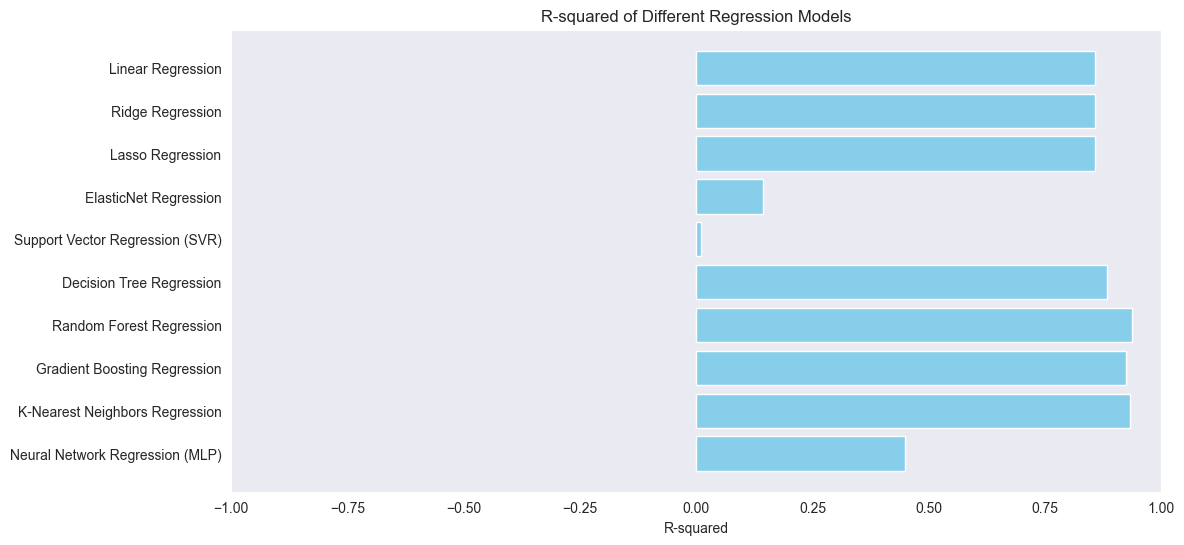

In [32]:
#Define Models and Perform Training and Evaluation

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0),
    'ElasticNet Regression': ElasticNet(alpha=1.0, l1_ratio=0.5),
    'Support Vector Regression (SVR)': SVR(kernel='rbf'),
    'Decision Tree Regression': DecisionTreeRegressor(),
    'Random Forest Regression': RandomForestRegressor(n_estimators=100),
    'Gradient Boosting Regression': GradientBoostingRegressor(n_estimators=100, learning_rate=0.1),
    'K-Nearest Neighbors Regression': KNeighborsRegressor(n_neighbors=5),
    'Neural Network Regression (MLP)': MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam')
}

# Train and evaluate each model
results = {'Model': [], 'MSE': [], 'R-squared': []}

for name, model in models.items():
    # Train the model
    model.fit(X_train, Y_train)

    # Predict on test set
    Y_pred = model.predict(X_test)

    # Evaluate model
    mse = mean_squared_error(Y_test, Y_pred)
    r2 = r2_score(Y_test, Y_pred)

    # Store results
    results['Model'].append(name)
    results['MSE'].append(mse)
    results['R-squared'].append(r2)

    # Print results
    print(f"----- {name} -----")
    print(f"Mean Squared Error (MSE): {mse}")
    print(f"R-squared: {r2}")
    print()

# Convert results to DataFrame for visualization
results_df = pd.DataFrame(results)
print(results_df)

# Plotting the results
plt.figure(figsize=(12, 6))
plt.barh(results_df['Model'], results_df['R-squared'], color='skyblue')
plt.xlabel('R-squared')
plt.title('R-squared of Different Regression Models')
plt.xlim(-1, 1)
plt.gca().invert_yaxis()
plt.show()


#Random Forest Regression is the best-performing model because it has the lowest MSE and the highest R-squared value among the 10 models you tested.
#Random Forest Regression is a powerful and versatile algorithm suitable for various regression tasks, offering robust performance and the ability to handle complex data relationships


# Saving the Model

In [34]:
import pickle
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
X, Y = make_regression(n_samples=1000, n_features=10, noise=0.1, random_state=0)


# Scale the features (optional but recommended for some algorithms)
scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize Random Forest Regressor
model_rf = RandomForestRegressor(n_estimators=100, random_state=0)

# Train the model
model_rf.fit(X_train, Y_train)

# Save the model to a file
filename = 'random_forest_model.pkl'
pickle.dump(model_rf, open(filename, 'wb'))

# Save scaler to a file
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# Load the model from the file
loaded_model = pickle.load(open(filename, 'rb'))

# Predict using the loaded model
Y_pred = loaded_model.predict(X_test)

# Evaluate the loaded model
mse = mean_squared_error(Y_test, Y_pred)
r2 = r2_score(Y_test, Y_pred)

print(f"Loaded Random Forest Regression - Mean Squared Error (MSE): {mse}")
print(f"Loaded Random Forest Regression - R-squared: {r2}")


Loaded Random Forest Regression - Mean Squared Error (MSE): 56153421.95967846
Loaded Random Forest Regression - R-squared: 0.9345143876439553
